In [1]:
# q1 - regressao linear bayesiana
# Levi Félix Barbosa - 579420

import numpy as np
import matplotlib.pyplot as plt

dados = np.loadtxt("linear_regression_data.csv", delimiter=",")
x, y = dados[:, 0], dados[:, 1]
N = len(x)
print(N, "pontos")

10 pontos


In [ ]:
# modelo: y = Xw + eps, eps ~ N(0, sigma2)
# priori: p(w) = N(w|m0, S0), com m0 = 0 e S0 = sigma_w2 * I
sigma2 = 0.04   # ruido com desvio ~0.2, chutei olhando a dispersao dos dados
sigma_w2 = 0.5

def phi(x):
    return np.c_[np.ones_like(x), x]  # x_i = [1, x_i]

X = phi(x)
M = X.shape[1]
m0 = np.zeros(M)
S0 = sigma_w2 * np.eye(M)

In [ ]:
# posteriori p(w|D) = N(w|mu, Sigma)
A = np.linalg.inv(S0 @ X.T @ X + sigma2 * np.eye(M)) @ S0
mu = m0 + A @ X.T @ (y - X @ m0)
Sigma = S0 - A @ X.T @ X @ S0

print("media a posteriori:", mu)
print("covariancia a posteriori:")
print(Sigma)

media a posteriori: [-0.2395928   0.51579897]
covariancia a posteriori:
[[ 0.00412407 -0.00177677]
 [-0.00177677  0.02026027]]


In [4]:
# preditiva: p(y*|x*) = N(y*|phi*^T mu, phi*^T Sigma phi* + sigma2)
def preditiva(xs, m, S):
    P = phi(xs)
    media = P @ m
    var = np.sum(P @ S * P, axis=1) + sigma2
    return media, np.sqrt(var)

xs = np.linspace(-1.2, 1.2, 200)

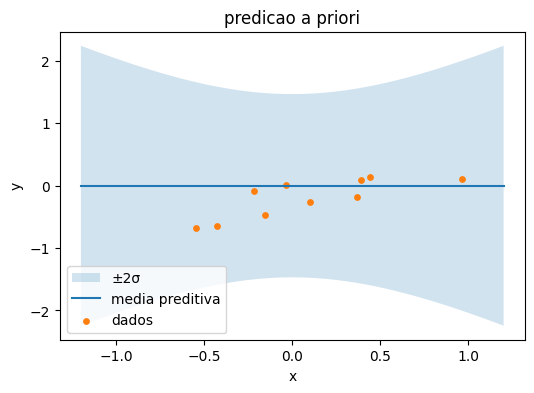

In [5]:
# a priori (mesma formula, trocando mu e Sigma por m0 e S0)
media, dp = preditiva(xs, m0, S0)

plt.figure(figsize=(6, 4))
plt.fill_between(xs, media - 2 * dp, media + 2 * dp, alpha=0.2, label="±2σ")
plt.plot(xs, media, label="media preditiva")
plt.scatter(x, y, s=15, label="dados")
plt.title("predicao a priori")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# antes de ver os dados a media e zero em todo lugar e a incerteza cresce
# conforme se afasta de x=0 (a reta pode ter qualquer inclinacao)

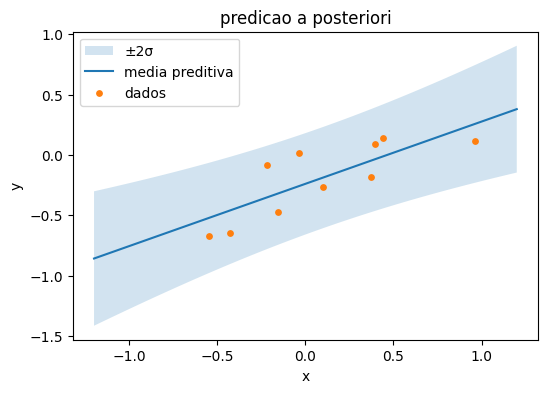

In [6]:
# a posteriori
media, dp = preditiva(xs, mu, Sigma)

plt.figure(figsize=(6, 4))
plt.fill_between(xs, media - 2 * dp, media + 2 * dp, alpha=0.2, label="±2σ")
plt.plot(xs, media, label="media preditiva")
plt.scatter(x, y, s=15, label="dados")
plt.title("predicao a posteriori")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# a faixa fica bem mais estreita, e o que sobra e basicamente o ruido
# das observacoes (sigma2), que nao some com mais dados